<a href="https://colab.research.google.com/github/ughadeayush767-code/MDM-Machine-Learning/blob/main/Practical_No_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
file = "wireless_signal_hierarchical_dataset.csv"
data = pd.read_csv(file)

# Fix CSV format and strip whitespace from all values
if len(data.columns) == 1:
    print("Single column detected. Fixing CSV format...")
    data = data.iloc[:, 0].str.split(",", expand=True)

# Strip whitespaces from all string cells
data = data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

data.columns = [
    "RSSI",
    "RSRP",
    "RSRQ",
    "SNR",
    "Latency",
    "Packet_Loss",
    "Status"
]

print("\nDataset Preview:")
print(data.head())

print("\nDataset Columns:")
print(data.columns)

Single column detected. Fixing CSV format...

Dataset Preview:
  RSSI RSRP RSRQ SNR Latency Packet_Loss  Status
0  -45   35    1  20      35          90  Normal
1  -50   32    2  25      36          88  Normal
2  -55   30    3  30      37          85  Normal
3  -60   28    5  40      40          80  Normal
4  -65   25    8  55      42          75   Fault

Dataset Columns:
Index(['RSSI', 'RSRP', 'RSRQ', 'SNR', 'Latency', 'Packet_Loss', 'Status'], dtype='object')


In [ ]:
# Sabhi numerical columns ko numeric banana aur errors ko NaN mein convert karna
feature_cols = ["RSSI", "RSRP", "RSRQ", "SNR", "Latency", "Packet_Loss"]
for col in feature_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Jo values numeric nahi thi unhe drop karna
data.dropna(subset=feature_cols, inplace=True)

print("\nMissing Values:")
print(data.isnull().sum())

print(f"\nRemaining Rows: {len(data)}")


Missing Values:
RSSI           0
RSRP           0
RSRQ           0
SNR            0
Latency        0
Packet_Loss    0
Status         0
dtype: int64

Remaining Rows: 20


In [ ]:
X = data[
    [
        "RSSI",
        "RSRP",
        "RSRQ",
        "SNR",
        "Latency",
        "Packet_Loss"
    ]
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

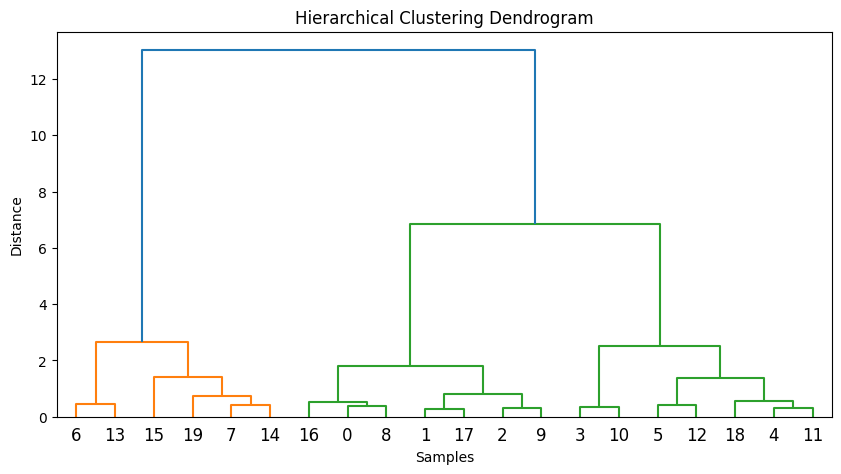

In [ ]:
plt.figure(figsize=(10, 5))

# Ward method use karke linkage calculate karna
linked = linkage(X_scaled, method="ward")

# Dendrogram plot karna
dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [ ]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Model fit karke labels data mein save karna
data["Cluster"] = model.fit_predict(X_scaled)

print("\nCluster Count:")
print(data["Cluster"].value_counts())


Cluster Count:
Cluster
2    7
1    7
0    6
Name: count, dtype: int64


In [ ]:
# Har cluster ka average RSSI nikalna
cluster_rssi = data.groupby("Cluster")["RSSI"].mean()
print("\nAverage RSSI:")
print(cluster_rssi)

# High RSSI = Good, Low RSSI = Poor
sorted_clusters = cluster_rssi.sort_values(ascending=False)

quality = {
    sorted_clusters.index[0]: "Good",
    sorted_clusters.index[1]: "Medium",
    sorted_clusters.index[2]: "Poor"
}

# Data mein map karna
data["Signal_Quality"] = data["Cluster"].map(quality)

print("\nFinal Classification:")
print(
    data[["RSSI", "RSRP", "SNR", "Cluster", "Signal_Quality"]]
)


Average RSSI:
Cluster
0   -77.500000
1   -64.428571
2   -49.857143
Name: RSSI, dtype: float64

Final Classification:
    RSSI  RSRP  SNR  Cluster Signal_Quality
0    -45    35   20        2           Good
1    -50    32   25        2           Good
2    -55    30   30        2           Good
3    -60    28   40        1         Medium
4    -65    25   55        1         Medium
5    -70    22   70        1         Medium
6    -75    18   90        0           Poor
7    -80    15  120        0           Poor
8    -48    34   22        2           Good
9    -53    31   35        2           Good
10   -58    29   45        1         Medium
11   -63    26   60        1         Medium
12   -68    23   75        1         Medium
13   -73    20   95        0           Poor
14   -78    16  110        0           Poor
15   -82    12  140        0           Poor
16   -46    36   18        2           Good
17   -52    33   28        2           Good
18   -67    24   65        1         Medium
19

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

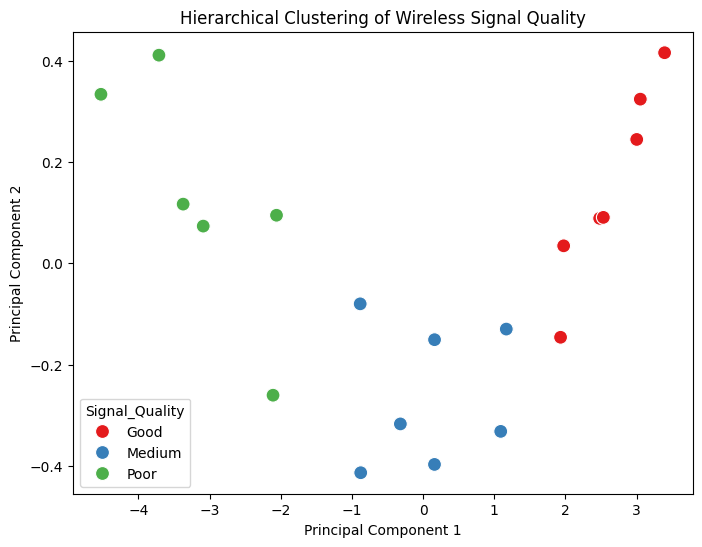

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=data["Signal_Quality"],
    palette="Set1",
    s=100
)

plt.title("Hierarchical Clustering of Wireless Signal Quality")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()